# 13 · Legacy Surveys galaxies in a mock WCC frame

Takes the **DESI Legacy Surveys Tractor** catalog (DR10, via NOIRLab Astro Data Lab), turns each resolved
galaxy into a `SersicComponent`, and simulates a WCC exposure with the real **Gaia** stars underneath.
The default pointing is the **COSMOS** field.

Needs network on the first run (Tractor, Gaia and the LS cutout are cached in `ls_cache/` afterwards).
The conversion code lives in `scripts/legacysurvey_galaxy_mock.py`; this notebook calls it.

**Prototype limits:** Tractor `PSF` rows are dropped (stars come from Gaia), each galaxy is one smooth Sersic,
and nothing is added below Tractor's depth (r ~ 23.5-24).

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

sys.path.insert(0, os.path.abspath("../scripts"))
import legacysurvey_galaxy_mock as lsm
from wcc_sim import detector_frame, simulate_field

warnings.filterwarnings("ignore", category=ResourceWarning)
plt.rcParams["figure.dpi"] = 110

## Settings

`SHAPE=None` simulates the full 9568 x 6380 detector (161" x 108"), which takes about five minutes.
The default subarray (35" x 52") renders in well under a minute and still holds ~100 galaxies.

In [2]:
RA, DEC = lsm.COSMOS          # try any sky position inside the Legacy Surveys footprint
SENSORFILTER = "zwo:r"        # zwo:g / zwo:r / zwo:i / zwo:z
SHAPE = (2048, 3072)          # (ny, nx); None = full detector
EXPTIME = 300.0               # s
DET_PA = 0.0                  # detector rotation, deg E of N
CACHE = "ls_cache"
SEED = 1

## 1. Query Tractor for this frame

In [3]:
frame = detector_frame(SENSORFILTER, (RA, DEC), pa=DET_PA, shape=SHAPE)
ny, nx = frame.shape
pix = frame.plate_scale_mas / 1000.0
half_diag = 0.5 * np.hypot(nx, ny) * pix
print(f"frame {nx} x {ny} px = {nx*pix:.0f}\" x {ny*pix:.0f}\" at {frame.plate_scale_mas:.2f} mas/px")

tractor = lsm.fetch_tractor(RA, DEC, half_diag + lsm.QUERY_MARGIN_ARCSEC, cache_dir=CACHE)
types, counts = np.unique(np.asarray(tractor["type"]).astype(str), return_counts=True)
print(len(tractor), "Tractor rows:", dict(zip(types, counts)))

frame 3072 x 2048 px = 52" x 35" at 16.87 mas/px
206 Tractor rows: {np.str_('DEV'): np.int64(8), np.str_('EXP'): np.int64(24), np.str_('PSF'): np.int64(78), np.str_('REX'): np.int64(87), np.str_('SER'): np.int64(9)}


## 2. Tractor rows to `SersicComponent`s

`EXP`/`REX` become n = 1, `DEV` n = 4, `SER` uses the fitted index. Ellipticity and position angle come from
`shape_e1`, `shape_e2` (PA east of north = ½·atan2(e2, e1), then carried onto the detector through the WCS).
Each AB magnitude in the WCC band is converted to the Gaia-G-equivalent that gives the same e-/s.

In [4]:
comps, truth = lsm.tractor_to_sersic(tractor, frame, SENSORFILTER)
print(len(comps), "Sersic components")
truth[:8]

123 Sersic components


ra,dec,type,n,r_eff_arcsec,ellip,pa_sky_deg,pa_pix_deg,mag_ab_band,total_mag_G
float64,float64,str3,float64,float64,float64,float64,float64,float64,float64
150.107349216093,2.186208024661336,SER,0.5,1.1517791748046875,0.4905244217539392,15.538882791295448,105.53936814270597,22.60448751197711,22.587427381699726
150.1132569175374,2.186604233166932,REX,1.0,0.22320598363876343,0.0,0.0,90.00025885468504,25.53474594556902,25.517685815291635
150.106472165793,2.188728124711548,DEV,4.0,0.1750839650630951,0.4351940730520809,43.3956164634001,133.396134756228,23.890289886944146,23.87322975666676
150.1112735418697,2.189895245952298,REX,1.0,0.8083758354187012,0.0,0.0,90.00033499189061,24.09728319665963,24.080223066382246
150.1101682511378,2.193954213109623,EXP,1.0,1.8462982177734375,0.5829561735613839,56.000399729675024,146.00077668126866,23.136294366617843,23.119234236340457
150.1117116371686,2.191196316485582,REX,1.0,0.4973474442958832,0.0,0.0,90.00031816883683,25.429821607359198,25.412761477081816
150.1076514210997,2.195899535847592,REX,1.0,0.43361225724220276,0.0,0.0,90.00047403519437,23.902268138397684,23.8852080081203
150.1104884912754,2.198934242627811,REX,1.0,0.31395283341407776,0.0,0.0,90.0003651217032,24.924862281807677,24.90780215153029


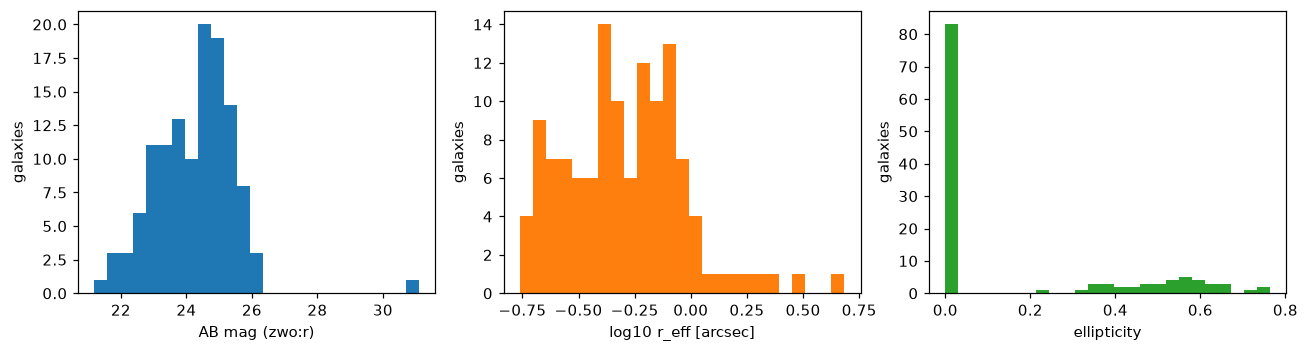

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].hist(truth["mag_ab_band"], bins=25, color="C0"); ax[0].set_xlabel(f"AB mag ({SENSORFILTER})")
ax[1].hist(np.log10(truth["r_eff_arcsec"]), bins=25, color="C1"); ax[1].set_xlabel("log10 r_eff [arcsec]")
ax[2].hist(truth["ellip"], bins=25, color="C2"); ax[2].set_xlabel("ellipticity")
for a in ax: a.set_ylabel("galaxies")
fig.tight_layout()

## 3. Simulate (galaxies + Gaia stars)

In [6]:
field = simulate_field(
    RA, DEC, sensorfilter=SENSORFILTER, exptime=EXPTIME, pa=DET_PA, shape=SHAPE,
    seed=SEED, extended_sources=comps, cache_dir=os.path.join(CACHE, "gaia"),
)
print(f"{field.image_adu.shape[::-1]} px, {len(field.catalog)} Gaia stars, "
      f"{int(field.saturation_mask.sum())} saturated px")

(3072, 2048) px, 2 Gaia stars, 0 saturated px


## 4. The mock image

Left: the noisy ADU frame. Right: the noise-free `CLEAN` frame (arcsinh stretch).

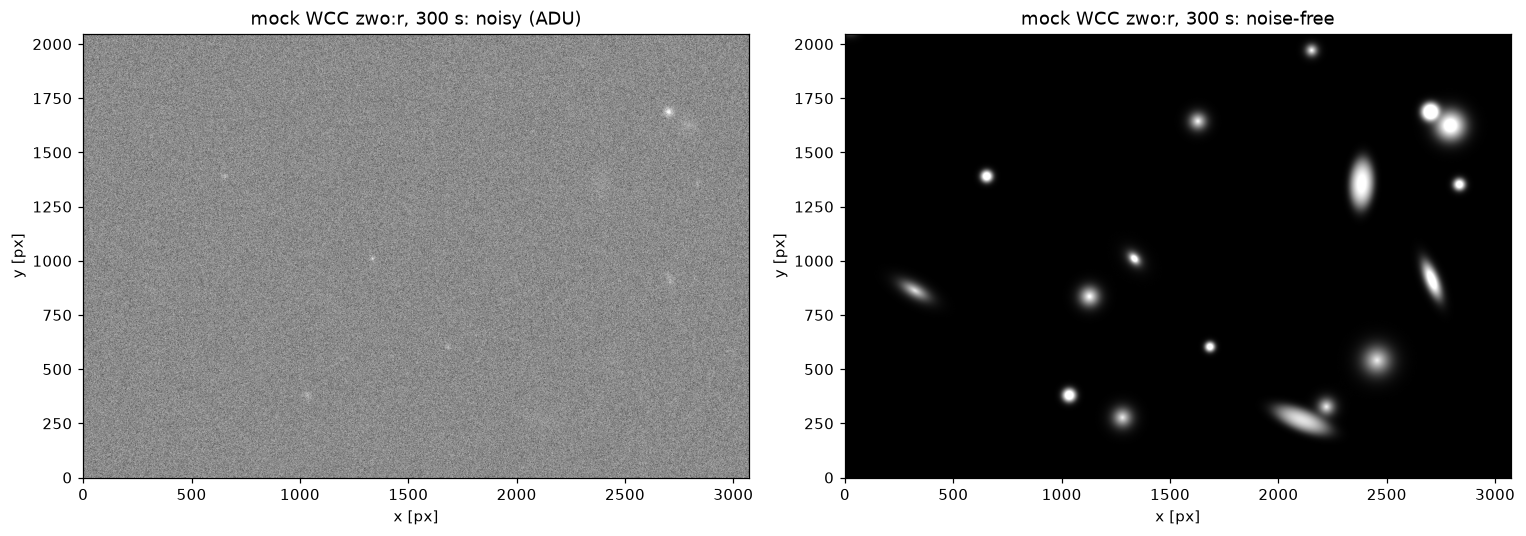

In [7]:
def stretch(img, lo_pct=5, hi_pct=99.8, soft=10.0):
    lo, hi = np.percentile(img, [lo_pct, hi_pct])
    return np.arcsinh((img - lo) / max(hi - lo, 1e-12) * soft) / np.arcsinh(soft)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, img, title in ((axes[0], field.image_adu, "noisy (ADU)"), (axes[1], field.image_clean, "noise-free")):
    ax.imshow(stretch(img), origin="lower", cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"mock WCC {SENSORFILTER}, {EXPTIME:.0f} s: {title}")
    ax.set_xlabel("x [px]"); ax.set_ylabel("y [px]")
fig.tight_layout()

## 5. Input shapes over the image

Ellipses are drawn at the half-light radius with the input axis ratio and angle, for the 40 brightest galaxies inside the frame.
If the angle convention were wrong they would visibly miss the elongation of the light.

Text(0.5, 1.0, 'half-light ellipses of the 17 brightest in-frame Tractor galaxies')

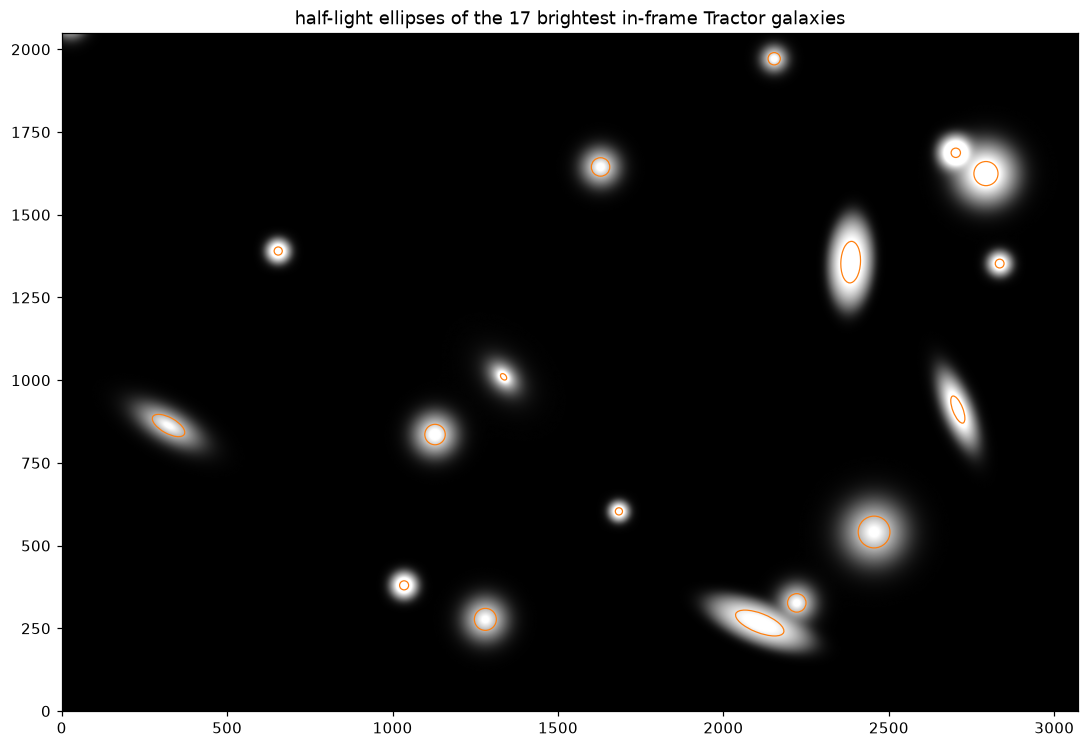

In [8]:
x, y = frame.wcs.world_to_pixel_values(truth["ra"], truth["dec"])
in_frame = (x > 0) & (x < nx) & (y > 0) & (y < ny)    # the query circle is larger than a subarray
order = [i for i in np.argsort(truth["mag_ab_band"]) if in_frame[i]]
bright = order[:40]
fig, ax = plt.subplots(figsize=(12, 12 * ny / nx))
ax.imshow(stretch(field.image_clean, hi_pct=99.5, soft=30.0), origin="lower", cmap="gray", vmin=0, vmax=1)
for i in bright:
    r = truth["r_eff_arcsec"][i] / pix
    ax.add_patch(Ellipse((x[i], y[i]), 2 * r, 2 * r * (1 - truth["ellip"][i]),
                         angle=truth["pa_pix_deg"][i], fill=False, ec="C1", lw=0.8))
ax.set_xlim(0, nx); ax.set_ylim(0, ny)
ax.set_title(f"half-light ellipses of the {len(bright)} brightest in-frame Tractor galaxies")

## 6. Zoom on the brightest galaxies

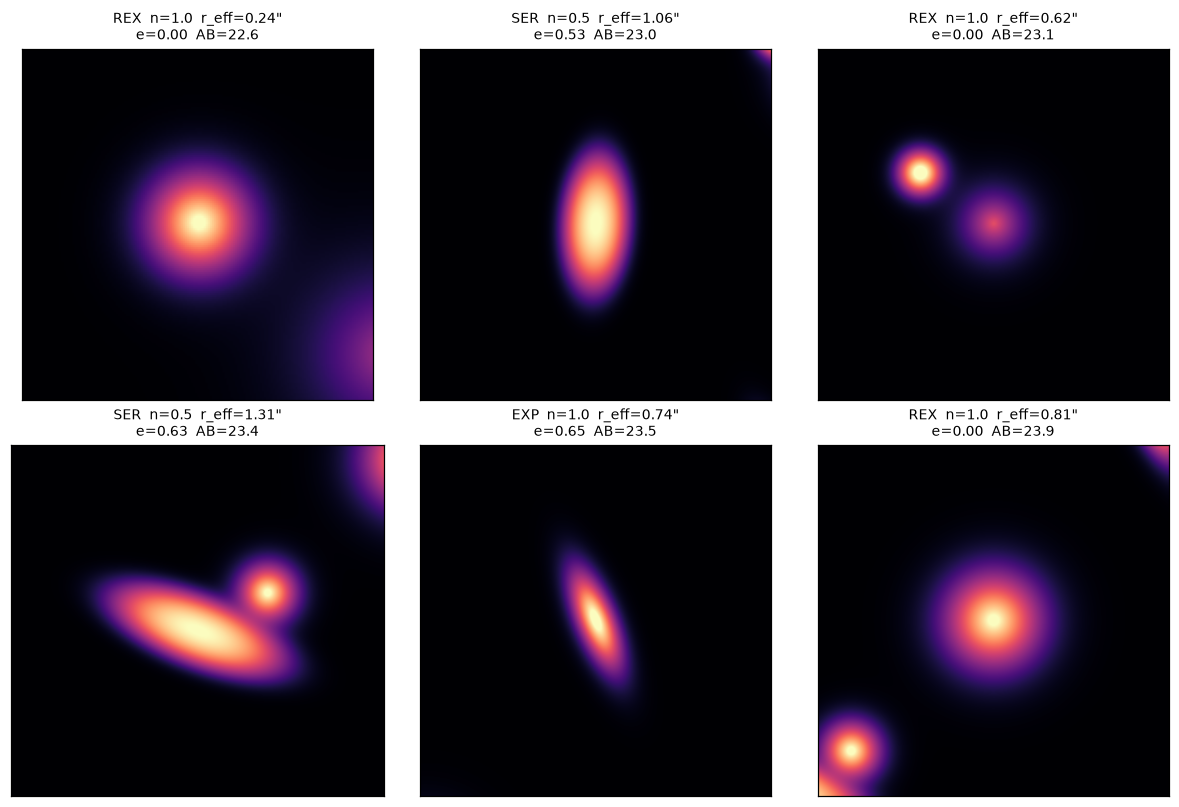

In [9]:
picked = [i for i in order if 100 < x[i] < nx - 100 and 100 < y[i] < ny - 100][:6]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, i in zip(axes.flat, picked):
    h = int(np.clip(6 * truth["r_eff_arcsec"][i] / pix, 40, 300))
    cx, cy = int(x[i]), int(y[i])
    cut = field.image_clean[max(cy - h, 0):cy + h, max(cx - h, 0):cx + h]
    ax.imshow(stretch(cut, 1, 99.9, 20.0), origin="lower", cmap="magma", vmin=0, vmax=1)
    ax.set_title(f"{truth['type'][i]}  n={truth['n'][i]:.1f}  r_eff={truth['r_eff_arcsec'][i]:.2f}\"\n"
                 f"e={truth['ellip'][i]:.2f}  AB={truth['mag_ab_band'][i]:.1f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## 7. Compare with the Legacy Surveys image

Fetches the LS-DR10 cutout of the same sky and shows it beside the mock, both on a coarse grid
(the LS pixel is 0.262" and its seeing about 1", so the mock is sharper by design).
Positions should line up one for one; the two stretches differ, so this is a qualitative check.

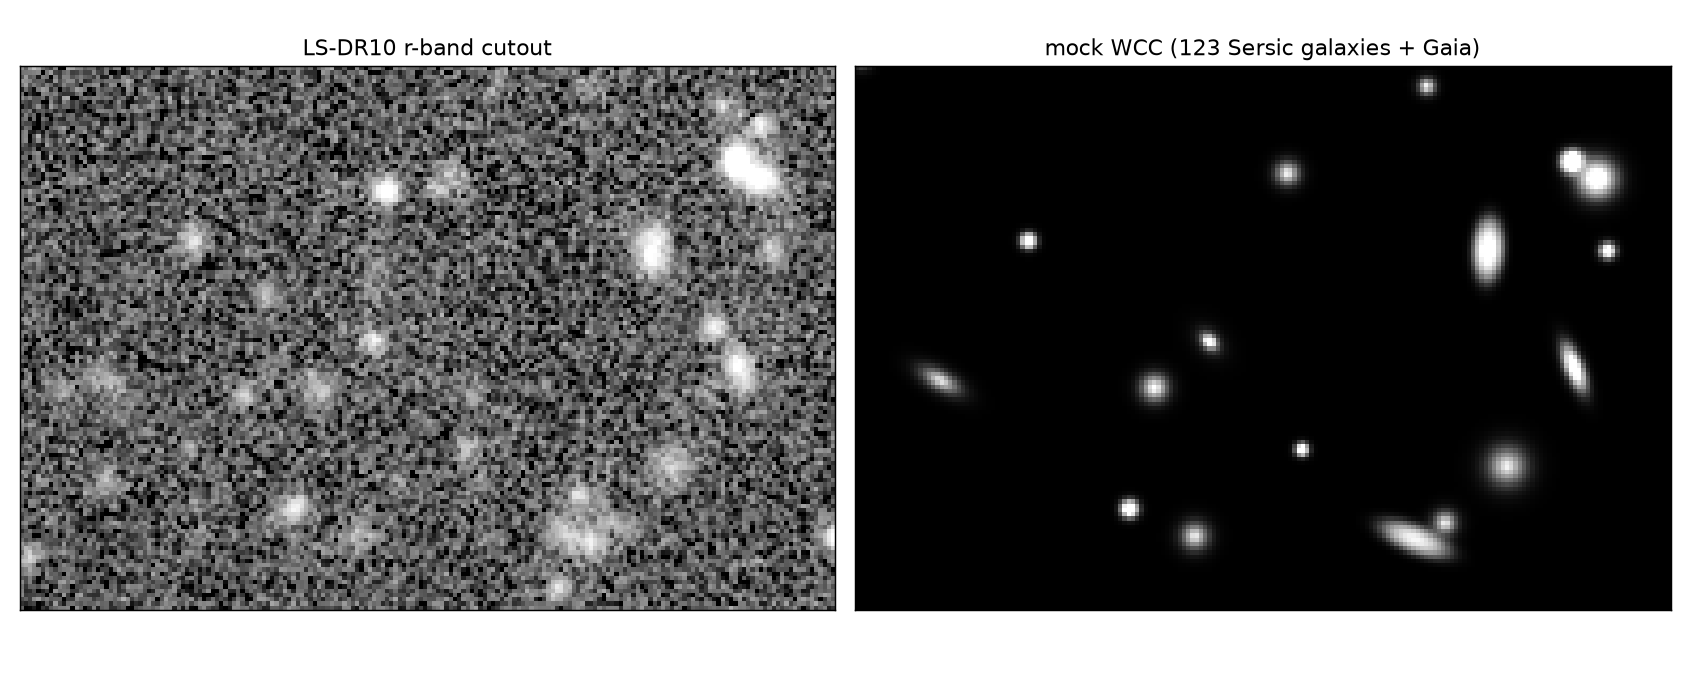

In [10]:
from IPython.display import Image, display
band = SENSORFILTER.split(":")[1]
band = band if band in ("g", "r", "z") else "r"
os.makedirs(CACHE, exist_ok=True)
out = os.path.join(CACHE, "mock_vs_legacysurvey.png")
lsm.plot_comparison(field, comps, RA, DEC, band, out)
display(Image(out))

## 8. Save

The FITS file has the usual `IMAGE`, `CLEAN`, `CAT` extensions plus the simulated frame's WCS.
The Tractor-derived truth table is saved alongside for later photometry checks.

In [11]:
field.write(os.path.join(CACHE, "mock_wcc.fits"))
truth.write(os.path.join(CACHE, "tractor_components.ecsv"), format="ascii.ecsv", overwrite=True)
print("wrote", os.listdir(CACHE))

wrote ['gaia', 'mock_vs_legacysurvey.png', 'tractor_components.ecsv', 'tractor_ls_dr10_150.12000_+2.20000_51.1.ecsv', 'mock_wcc.fits']
